# Run plane estimation with different paramaters

A notebook to see what the estimation error iS for different parameters. Generates some planar routes and lets tge plane esstimate work. Saves the error and plots it.


## Setup

In [5]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Colab. Uncomment this block there, then the working directory is the repo root.
# %cd /content
# !rm -rf /content/CAN_Path_Integration_3D_model
# !git clone --branch main --single-branch https://github.com/jacobsvennevik/CAN_Path_Integration_Plane_estimation_3D_model.git /content/CAN_Path_Integration_3D_model
# %cd /content/CAN_Path_Integration_3D_model

#for local running
sys.path.insert(0, os.path.abspath("../.."))

from experiments.arena_3d_planar_routes import (
    Arena3DPlanarRoutesConfig, make_planar_routes_trajectory,
)
from model.path_integration import step_filter
from model.plane_estimation import held_normal_stats, sample_vmf, uniform_prior
from model.network.visualize3D import plot_plane_rms, plot_plane_rms_grid


## Replay

Generate the trajectories and the true normals. Then let the plane estimation run over the routes, with same logic as in pathintegretion


In [6]:
route_cfg = Arena3DPlanarRoutesConfig(
    env_size=2.0, seed=0, n_routes=25, round_trips=2,
    grid_spacing=0.48, target_speed_rad_per_time=0.02,
)
routes = make_planar_routes_trajectory(
    route_cfg, dt=0.25, scale=1.0046 / 0.48, dim=2,
    rng=np.random.default_rng(0),
)
v_body = routes.v_body_seq
n_true = routes.n_true_seq
g_hat = np.array([0.0, 0.0, -9.81])
g_hat = g_hat / np.linalg.norm(g_hat)

KAPPAS = (1_000_000.0, 100_000, 10_000.0, 1_000.0, 100.0, 10.0, 1)
TAUS = (1, 50, 100, 1_000, 10_000, 100_000)


def held_for(kappa_sens, tau_refresh):
    """ It replay one plane setting over the route and record the normal that would be held at each step.
    
    Copied from _advance in the pathintegrator so this cell does not do anything on the sheet.
    """
    #start the belief with no preffered direction
    state = uniform_prior()
    rng = np.random.default_rng(0)
    #refersh intervall steps
    refresh = np.arange(len(v_body)) % int(tau_refresh) == 0
    n_held = None
    #one held normal for each step
    held = np.empty_like(n_true)
    for t, (v, n_ref) in enumerate(zip(v_body, n_true)):
        #normalize the true normal
        n_ref = n_ref / np.linalg.norm(n_ref)
        #skip if barely moves
        if np.linalg.norm(v) > 1e-9:
            #draws one noisy unit vector around the true normal, 
            # Large kappa_sens keeps it close to the truth
            z = sample_vmf(n_ref, kappa_sens, rng)
            #folds that precept into the belief
            state = step_filter(state, z, kappa_sens)
        #the belief is now a vector, not a distribution
        n_hat = np.asarray(state.mu, dtype=float).copy()
        #if the belief is in the same hemisphere as gravity, flip it
        if np.dot(n_hat, g_hat) > 0:
            n_hat = -n_hat
        if refresh[t] or n_held is None:
            n_held = n_hat
        held[t] = n_held
    return held, refresh


## Run

In [7]:
rows = []
for kappa in KAPPAS:
    for tau in TAUS:
        held, refresh = held_for(kappa, tau)
        stats = held_normal_stats(held, n_true, refresh)
        rows.append(dict(
            kappa_sens=kappa, tau_refresh=tau,
            rms_err_deg=stats["rms_err_deg"],
            mean_rate_deg=stats["mean_rate_deg"],
            refresh_count=stats["refresh_count"],
        ))




## Plot results

,kappa_sens,tau_refresh,rms_err_deg,mean_rate_deg,refresh_count
0,1000000.0,1,0.151489,0.131655,82760
1,1000000.0,50,7.112977,0.033563,1656
2,1000000.0,100,9.719268,0.032563,828
3,1000000.0,1000,29.020485,0.031629,83
4,1000000.0,10000,53.394338,0.004722,9
5,1000000.0,100000,38.279928,0.000000,1
6,100000.0,1,0.284858,0.314026,82760
7,100000.0,50,7.115196,0.037382,1656
8,100000.0,100,9.721041,0.034438,828
9,100000.0,1000,29.011774,0.031694,83


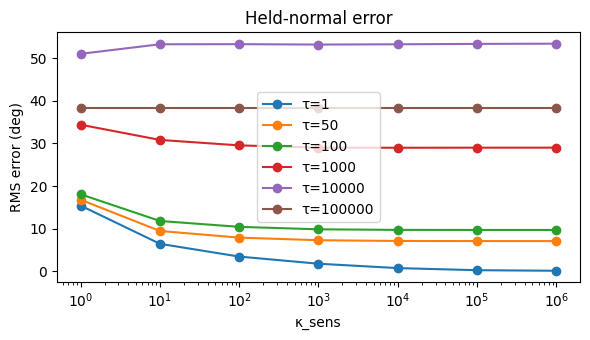

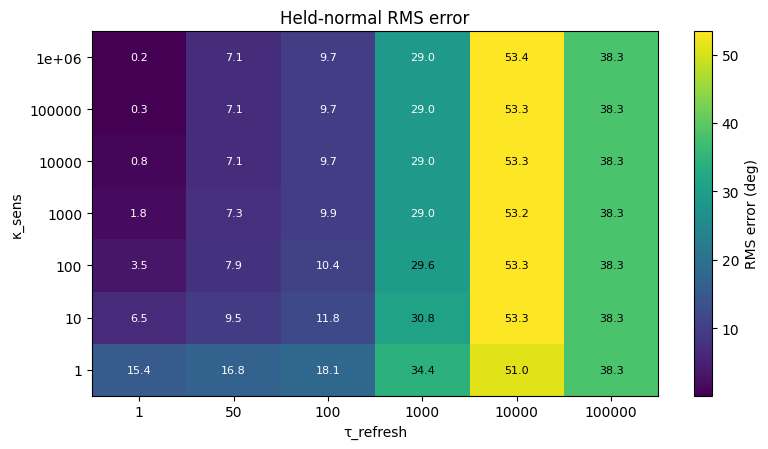

In [8]:
plane_df = pd.DataFrame(rows)
display(plane_df)

fig, _ = plot_plane_rms(
    plane_df["kappa_sens"], plane_df["tau_refresh"], plane_df["rms_err_deg"],
)
plt.show()

fig, _ = plot_plane_rms_grid(
    plane_df["kappa_sens"], plane_df["tau_refresh"], plane_df["rms_err_deg"],
)
plt.show()